# Analyse Exploratoire des Données (EDA) — REFIT

## Dataset : REFIT Electrical Load Measurements (Cleaned)

### University of Strathclyde / Loughborough — 20 foyers, Royaume-Uni

**Période :** Octobre 2013 – Juin 2015 (~2 ans par foyer)

**Objectifs :**
1. Charger les 20 foyers REFIT (agrégat de puissance + colonne `Issues`)
2. Convertir et rééchantillonner les séries à la résolution 1 minute (alignement avec le pipeline UCI)
3. Nettoyer les données (complétude, valeurs suspectes signalées par `Issues`)
4. Explorer la complétude et la diversité des profils entre foyers
5. Charger et structurer les métadonnées ménages (occupation, type de logement, année de construction)
6. Produire des séries propres, prêtes pour le feature engineering (Notebook 02)

Ce notebook réplique la méthodologie de `02_EDA_Household_Power_Consumption` (foyer UCI, France),
appliquée cette fois à 20 foyers britanniques, comme deuxième jambe (« 2nd leg ») du projet.

AUTEUR : ENANGA DANIEL CHRISTIAN
ANNÉE ACADÉMIQUE : 2025 – 2026


## Étape 0 : Imports des bibliothèques

In [1]:
# --- Bibliothèques standard ---
import os
import re
import glob
import warnings

# --- Data Science ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# --- Lecture des métadonnées Excel ---
from openpyxl import load_workbook

warnings.filterwarnings('ignore')

# Style des graphiques (identique au pipeline UCI)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 150

print("Bibliothèques chargées avec succès !")


Bibliothèques chargées avec succès !


## Étape 1 : Configuration et chemins

**Rappel de la structure attendue des données brutes (voir README du projet) :**

```
data/raw/
├── refit/
│   ├── house-1.csv
│   ├── house-2.csv
│   ├── ...
│   └── house-21.csv        (house-14 n'existe pas — normal)
├── CLEAN_READ_ME_081116.txt
└── MetaData_Tables.xlsx
```

Télécharger `CLEAN_REFIT_081116.7z` depuis
https://pureportal.strath.ac.uk/en/datasets/refit-electrical-load-measurements-cleaned/
et extraire les 20 fichiers `house-N.csv` dans `data/raw/refit/`.


In [2]:
# Chemin vers la racine du projet
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

RAW_DIR = os.path.join(BASE_DIR, "data", "raw")
REFIT_DIR = os.path.join(RAW_DIR, "refit")
PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed", "refit")
IMAGES_DIR = os.path.join(BASE_DIR, "images", "EDA_REFIT")
METADATA_PATH = os.path.join(RAW_DIR, "MetaData_Tables.xlsx")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(IMAGES_DIR, exist_ok=True)

# Les 20 foyers REFIT (House 14 n'existe pas)
HOUSE_IDS = [i for i in range(1, 22) if i != 14]
print(f"Nombre de foyers REFIT attendus : {len(HOUSE_IDS)}")
print(f"Répertoire des données brutes REFIT : {REFIT_DIR}")


Nombre de foyers REFIT attendus : 20
Répertoire des données brutes REFIT : c:\Users\Christian Enanga\Dossier-du-TFC\TFC-electricity-clustering\paper\refit_project\data\raw\refit


## Étape 2 : Chargement des métadonnées ménages

Les métadonnées (occupation, année de construction, nombre d'appareils, type de logement,
taille) sont indispensables pour la validation externe des clusters au Niveau 2
(Notebook 04) — c'est la pièce la plus précieuse de tout ce projet, à ne jamais perdre.


In [3]:
def parse_construction_year(raw) -> float:
    """
    Convertit les valeurs hétérogènes de la colonne 'Construction Year'
    (ex: '1975-1980', 'post 2002', 'mid 60s', '1988', '-') en une année
    numérique représentative (milieu de fourchette). Retourne np.nan si
    l'information est absente ('-').
    """
    if raw is None:
        return np.nan
    s = str(raw).strip().strip('\t').strip()
    if s in ('-', '', 'nan'):
        return np.nan

    s_lower = s.lower()
    if 'post' in s_lower:
        digits = re.findall(r'\d{4}', s)
        return float(digits[0]) + 2 if digits else np.nan
    if 'mid' in s_lower:
        digits = re.findall(r'\d{2}', s)
        if digits:
            decade = int(digits[0])
            century = 1900 if decade > 30 else 2000  # heuristique raisonnable pour ce dataset (1960s)
            return float(century + decade + 5)
        return np.nan

    # Plage 'YYYY-YYYY'
    range_match = re.findall(r'(\d{4})\s*-\s*(\d{4})', s)
    if range_match:
        y1, y2 = range_match[0]
        return (int(y1) + int(y2)) / 2

    # Année unique
    single_match = re.findall(r'\d{4}', s)
    if single_match:
        return float(single_match[0])

    return np.nan


def parse_bedrooms(raw) -> float:
    """Extrait le nombre de chambres depuis une chaîne comme '4 bed'."""
    if raw is None:
        return np.nan
    digits = re.findall(r'\d+', str(raw))
    return float(digits[0]) if digits else np.nan


def load_refit_metadata(path: str) -> pd.DataFrame:
    """
    Charge et nettoie la feuille 'Sheet1' (Household Information) du fichier
    MetaData_Tables.xlsx fourni avec REFIT. Les valeurs brutes contiennent
    des tabulations parasites (ex: '1\\t', '\\t2\\t') qu'il faut nettoyer.
    """
    wb = load_workbook(path, read_only=True, data_only=True)
    ws = wb["Sheet1"]
    rows = list(ws.iter_rows(values_only=True))

    # Les deux premières lignes sont un titre puis les en-têtes de colonnes
    data_rows = rows[2:]

    records = []
    for row in data_rows:
        if row[0] is None:
            continue
        house_id = int(re.findall(r'\d+', str(row[0]))[0])
        occupancy = int(re.findall(r'\d+', str(row[1]))[0])
        construction_year = parse_construction_year(row[2])
        appliances_owned = int(row[3]) if row[3] is not None else np.nan
        house_type = str(row[4]).strip().strip('\t').strip()
        bedrooms = parse_bedrooms(row[5])
        records.append({
            "house_id": house_id,
            "occupancy": occupancy,
            "construction_year": construction_year,
            "appliances_owned": appliances_owned,
            "house_type": house_type,
            "bedrooms": bedrooms,
        })

    return pd.DataFrame(records).sort_values("house_id").reset_index(drop=True)


df_metadata = load_refit_metadata(METADATA_PATH)
print(f"Métadonnées chargées : {df_metadata.shape[0]} foyers")
df_metadata


Métadonnées chargées : 20 foyers


,house_id,occupancy,construction_year,appliances_owned,house_type,bedrooms
0,1,2,1977.5,35,Detached,4.0
1,2,4,NaN,15,Semi-detached,3.0
2,3,2,1988.0,27,Detached,3.0
3,4,2,1874.5,33,Detached,4.0
4,5,4,1878.0,44,Mid-terrace,4.0
5,6,2,2005.0,49,Detached,4.0
6,7,4,1969.5,25,Detached,3.0
7,8,2,1966.0,35,Detached,2.0
8,9,2,1931.5,24,Detached,3.0
9,10,4,1931.5,31,Detached,3.0


In [4]:
# Sauvegarde des métadonnées nettoyées (réutilisées au Notebook 04)
metadata_out_path = os.path.join(PROCESSED_DIR, "household_metadata_clean.csv")
df_metadata.to_csv(metadata_out_path, index=False)
print(f"Métadonnées nettoyées sauvegardées : {metadata_out_path}")

print("\n=== Statistiques descriptives des métadonnées ===")
print(df_metadata[["occupancy", "construction_year", "appliances_owned", "bedrooms"]].describe())
print("\nRépartition par type de logement :")
print(df_metadata["house_type"].value_counts())


Métadonnées nettoyées sauvegardées : c:\Users\Christian Enanga\Dossier-du-TFC\TFC-electricity-clustering\paper\refit_project\data\processed\refit\household_metadata_clean.csv

=== Statistiques descriptives des métadonnées ===
       occupancy  construction_year  appliances_owned   bedrooms
count  20.000000          19.000000         20.000000  20.000000
mean    2.900000        1961.684211         30.400000   3.300000
std     1.293709          36.154073          9.247475   0.656947
min     1.000000        1874.500000         15.000000   2.000000
25%     2.000000        1954.500000         24.750000   3.000000
50%     2.500000        1969.500000         27.500000   3.000000
75%     4.000000        1985.500000         35.000000   4.000000
max     6.000000        2005.000000         49.000000   5.000000

Répartition par type de logement :
house_type
Detached         16
Semi-detached     3
Mid-terrace       1
Name: count, dtype: int64


## Étape 3 : Fonction de chargement générique d'un foyer REFIT

Chaque fichier `house-N.csv` suit le format documenté dans le README :
`DATETIME, UNIX TIMESTAMP (UCT), Aggregate, Appliance1, ..., Appliance9, Issues`
(13 colonnes). Seules `DATETIME` et `Aggregate` nous intéressent ici — l'agrégat
joue le rôle de `Global_active_power` dans le pipeline UCI.

**Points d'attention (voir README REFIT) :**
- La puissance est en **Watts** → conversion en kW (÷1000) pour rester cohérent avec le pipeline UCI.
- Résolution native ≈ 8 secondes → rééchantillonnage à **1 minute** (moyenne), ce qui aligne
  exactement la granularité sur celle du foyer UCI (1440 points/jour).
- La colonne `Issues` vaut 1 si la somme des sous-compteurs dépasse l'agrégat (incohérence de mesure) :
  ces minutes sont exclues plutôt que traitées comme fiables.
- Certains exports REFIT n'ont pas de ligne d'en-tête : la fonction détecte ce cas automatiquement.


In [5]:
REFIT_COLUMNS = ["DateTime", "Unix", "Aggregate"] + [f"Appliance{i}" for i in range(1, 10)] + ["Issues"]


def find_refit_house_file(house_id: int, refit_dir: str) -> str | None:
    """
    Localise le fichier correspondant à un foyer REFIT, quel que soit le nom
    exact donné par la source de téléchargement. Selon la plateforme utilisée,
    les fichiers peuvent s'appeler 'house-1.csv', 'House_1.csv',
    'CLEAN_House1.csv', 'CLEAN_House1' (sans extension), etc.

    La recherche se fait par expression régulière sur le numéro de foyer,
    avec une garde anti-collision (?!\\d) pour ne jamais confondre, par
    exemple, le foyer 1 avec le foyer 11 ou 19.
    """
    if not os.path.isdir(refit_dir):
        return None

    pattern = re.compile(rf"house[_\-]?0*{house_id}(?!\d)", re.IGNORECASE)
    candidates = sorted(f for f in os.listdir(refit_dir) if pattern.search(f))

    if not candidates:
        return None
    if len(candidates) > 1:
        print(f"  [ATTENTION] plusieurs fichiers correspondent au foyer {house_id} : {candidates} "
              f"-> utilisation de '{candidates[0]}'.")
    return os.path.join(refit_dir, candidates[0])


def load_refit_house_raw(house_id: int, refit_dir: str = REFIT_DIR) -> pd.DataFrame | None:
    """
    Charge le CSV brut d'un foyer REFIT (quel que soit son nom exact, voir
    find_refit_house_file) et retourne un DataFrame avec colonnes
    ['DateTime', 'Aggregate', 'Issues'] uniquement.
    Retourne None si le fichier est introuvable (avec un avertissement).
    """
    path = find_refit_house_file(house_id, refit_dir)

    if path is None:
        print(f"  [ATTENTION] Aucun fichier trouvé pour le foyer {house_id} dans {refit_dir} — foyer ignoré.")
        return None

    # Détection de la présence d'une ligne d'en-tête
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        first_line = f.readline()
    has_header = not first_line.strip().split(",")[0].replace("-", "").isdigit()

    if has_header:
        df = pd.read_csv(path, low_memory=False)
        df = df.iloc[:, :13]
        df.columns = REFIT_COLUMNS
    else:
        df = pd.read_csv(path, header=None, names=REFIT_COLUMNS, low_memory=False)

    df = df[["DateTime", "Aggregate", "Issues"]].copy()
    df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")
    df["Aggregate"] = pd.to_numeric(df["Aggregate"], errors="coerce")
    df["Issues"] = pd.to_numeric(df["Issues"], errors="coerce").fillna(0)
    df = df.dropna(subset=["DateTime"]).sort_values("DateTime")
    return df


def clean_and_resample_house(df_raw: pd.DataFrame, house_id: int) -> pd.Series:
    """
    Nettoie et rééchantillonne la série d'un foyer à la résolution 1 minute.

    - Exclut les lignes signalées par Issues == 1 (incohérence sous-compteurs / agrégat).
    - Convertit W -> kW.
    - Rééchantillonne à 1 minute (moyenne), alignant la granularité sur le pipeline UCI.
    """
    df = df_raw[df_raw["Issues"] == 0].copy()
    df = df.set_index("DateTime")
    power_w = df["Aggregate"]

    power_w_1min = power_w.resample("1min").mean()
    power_kw_1min = power_w_1min / 1000.0
    power_kw_1min.name = f"house_{house_id}"
    return power_kw_1min


print("Fonctions de chargement définies.")


Fonctions de chargement définies.


## Étape 4 : Chargement, nettoyage et résumé de complétude — 20 foyers

In [6]:
completeness_rows = []
cleaned_series = {}

print("=" * 70)
print("CHARGEMENT DES 20 FOYERS REFIT")
print("=" * 70)

for house_id in HOUSE_IDS:
    print(f"\n--- Foyer {house_id} ---")
    df_raw = load_refit_house_raw(house_id)
    if df_raw is None:
        continue

    n_rows_raw = len(df_raw)
    n_issues = int((df_raw["Issues"] == 1).sum())
    date_min, date_max = df_raw["DateTime"].min(), df_raw["DateTime"].max()

    power_clean = clean_and_resample_house(df_raw, house_id)
    n_expected_minutes = int((power_clean.index.max() - power_clean.index.min()).total_seconds() / 60) + 1
    pct_complete = 100 * power_clean.notna().sum() / max(n_expected_minutes, 1)

    cleaned_series[house_id] = power_clean

    completeness_rows.append({
        "house_id": house_id,
        "n_rows_raw": n_rows_raw,
        "n_issues_flagged": n_issues,
        "date_min": date_min,
        "date_max": date_max,
        "n_minutes_resampled": len(power_clean),
        "pct_complete": round(pct_complete, 2),
    })

    print(f"  Période : {date_min} -> {date_max}")
    print(f"  Lignes brutes : {n_rows_raw:,} | Issues signalées : {n_issues:,}")
    print(f"  Complétude après rééchantillonnage 1 min : {pct_complete:.1f}%")

df_completeness = pd.DataFrame(completeness_rows)
print("\n" + "=" * 70)
print(f"RÉSUMÉ : {len(cleaned_series)} / {len(HOUSE_IDS)} foyers chargés avec succès")
print("=" * 70)
df_completeness


CHARGEMENT DES 20 FOYERS REFIT

--- Foyer 1 ---
  Période : 2013-10-09 13:06:17 -> 2015-07-10 11:56:32
  Lignes brutes : 6,960,008 | Issues signalées : 58,183
  Complétude après rééchantillonnage 1 min : 87.0%

--- Foyer 2 ---
  Période : 2013-09-17 22:08:11 -> 2015-05-28 08:05:43
  Lignes brutes : 5,733,526 | Issues signalées : 28,444
  Complétude après rééchantillonnage 1 min : 75.3%

--- Foyer 3 ---
  Période : 2013-09-25 19:21:09 -> 2015-06-02 10:55:42
  Lignes brutes : 6,994,594 | Issues signalées : 408,627
  Complétude après rééchantillonnage 1 min : 84.6%

--- Foyer 4 ---
  Période : 2013-10-11 10:19:17 -> 2015-07-07 09:57:38
  Lignes brutes : 6,760,511 | Issues signalées : 67,441
  Complétude après rééchantillonnage 1 min : 85.9%

--- Foyer 5 ---
  Période : 2013-09-26 09:56:09 -> 2015-07-06 17:48:55
  Lignes brutes : 7,430,755 | Issues signalées : 425,766
  Complétude après rééchantillonnage 1 min : 86.8%

--- Foyer 6 ---
  Période : 2013-11-28 12:15:35 -> 2015-06-28 22:14:45


,house_id,n_rows_raw,n_issues_flagged,date_min,date_max,n_minutes_resampled,pct_complete
0,1,6960008,58183,2013-10-09 13:06:17,2015-07-10 11:56:32,920091,86.96
1,2,5733526,28444,2013-09-17 22:08:11,2015-05-28 08:05:43,889078,75.30
2,3,6994594,408627,2013-09-25 19:21:09,2015-06-02 10:55:42,885095,84.62
3,4,6760511,67441,2013-10-11 10:19:17,2015-07-07 09:57:38,912939,85.95
4,5,7430755,425766,2013-09-26 09:56:09,2015-07-06 17:48:55,933593,86.75
5,6,6241971,34451,2013-11-28 12:15:35,2015-06-28 22:14:45,831480,84.65
6,7,6756034,161919,2013-11-01 22:01:18,2015-07-08 02:10:54,882970,86.32
7,8,6118469,25000,2013-11-01 22:13:18,2015-05-10 23:36:10,799284,89.68
8,9,6169525,32226,2013-12-17 17:26:20,2015-07-08 18:52:50,818007,84.57
9,10,6739284,30162,2013-11-20 11:31:18,2015-06-30 11:07:07,845257,88.71


**Note de rigueur :** si `df_completeness` est vide ci-dessus, c'est que les fichiers
`house-N.csv` n'ont pas encore été placés dans `data/raw/refit/` (voir Étape 1). Ce notebook est
conçu pour signaler proprement les fichiers manquants plutôt que d'échouer silencieusement —
téléchargez les données puis relancez cette cellule.

In [7]:
if not df_completeness.empty:
    # Foyers avec une complétude trop faible pour être exploités sereinement
    LOW_COMPLETENESS_THRESHOLD = 70.0  # %, seuil à documenter/ajuster dans l'article
    low_completeness = df_completeness[df_completeness["pct_complete"] < LOW_COMPLETENESS_THRESHOLD]
    if not low_completeness.empty:
        print(f"Foyers sous le seuil de {LOW_COMPLETENESS_THRESHOLD}% de complétude :")
        print(low_completeness[["house_id", "pct_complete"]])
    else:
        print(f"Tous les foyers dépassent le seuil de {LOW_COMPLETENESS_THRESHOLD}% de complétude.")


Tous les foyers dépassent le seuil de 70.0% de complétude.


## Étape 5 : Visualisation d'exemples (foyers contrastés)

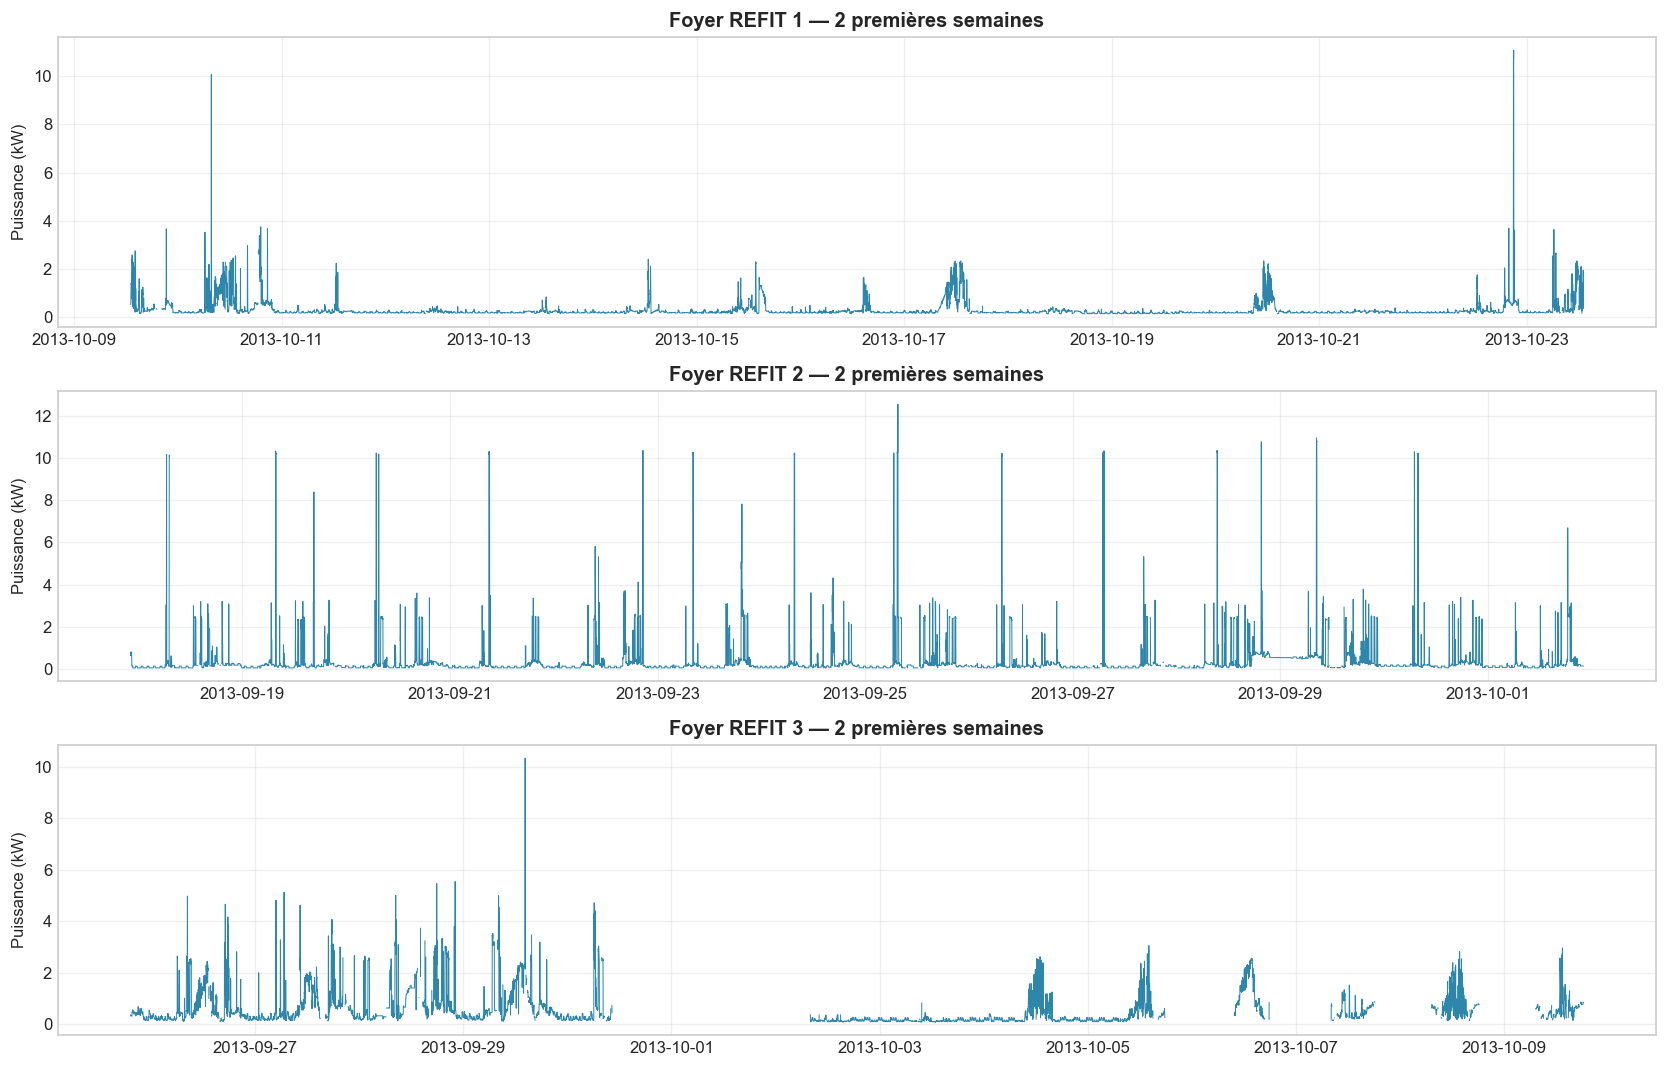

Figure sauvegardée : 01_exemples_foyers_refit.png


In [ ]:
if cleaned_series:
    sample_houses = list(cleaned_series.keys())[:3]
    fig, axes = plt.subplots(len(sample_houses), 1, figsize=(14, 3 * len(sample_houses)), sharex=False)
    if len(sample_houses) == 1:
        axes = [axes]

    for ax, house_id in zip(axes, sample_houses):
        series = cleaned_series[house_id]
        two_weeks = series.iloc[: 14 * 24 * 60] if len(series) > 14 * 24 * 60 else series
        ax.plot(two_weeks.index, two_weeks.values, linewidth=0.6, color="#2E86AB")
        ax.set_title(f"Foyer REFIT {house_id} — 2 premières semaines", fontweight="bold")
        ax.set_ylabel("Puissance (kW)")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, "01_exemples_foyers_refit.png"), dpi=300, bbox_inches="tight")
    plt.show()
    print("Figure sauvegardée : 01_exemples_foyers_refit.png")
else:
    print("Aucune donnée chargée — voir note de rigueur ci-dessus.")


## Étape 6 : Sauvegarde des séries nettoyées

In [9]:
for house_id, series in cleaned_series.items():
    out_path = os.path.join(PROCESSED_DIR, f"house_{house_id}_clean.csv")
    series.to_frame("power_kw").to_csv(out_path)

completeness_out_path = os.path.join(PROCESSED_DIR, "refit_completeness_summary.csv")
df_completeness.to_csv(completeness_out_path, index=False)

print(f"{len(cleaned_series)} séries nettoyées sauvegardées dans : {PROCESSED_DIR}")
print(f"Résumé de complétude sauvegardé : {completeness_out_path}")


20 séries nettoyées sauvegardées dans : c:\Users\Christian Enanga\Dossier-du-TFC\TFC-electricity-clustering\paper\refit_project\data\processed\refit
Résumé de complétude sauvegardé : c:\Users\Christian Enanga\Dossier-du-TFC\TFC-electricity-clustering\paper\refit_project\data\processed\refit\refit_completeness_summary.csv


## Résumé final

**Fichiers produits :**
- `data/processed/refit/house_<id>_clean.csv` — une série 1 minute par foyer (kW)
- `data/processed/refit/refit_completeness_summary.csv` — complétude par foyer
- `data/processed/refit/household_metadata_clean.csv` — métadonnées ménages nettoyées
- `images/EDA_REFIT/01_exemples_foyers_refit.png`

**Étape suivante :** Notebook `02_Feature_Engineering_REFIT.ipynb` — construction des 7 features
journalières pour chacun des 20 foyers, avec la même fonction que celle utilisée sur le foyer UCI.
